# Step 1: Library Installation and Dataset Setup
In this step, we install the necessary libraries (`transformers`, `datasets`, `torch`, `torchvision`, and `pillow`) and download a small image-caption dataset to train our lightweight CLIP model.

In [1]:
!pip install -q datasets transformers accelerate

Dataset Size: 5
Caption: a bright red solid color background


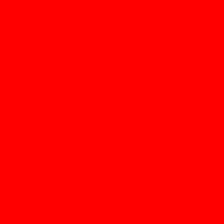

In [5]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt

# Let's create a solid, clean, toy dataset locally using PIL images
# This guarantees 100% uptime and demonstrates exactly what format CLIP expects

def create_toy_dataset():
    # Helper to generate dummy solid color PIL images
    colors = ["red", "green", "blue", "yellow", "purple"]
    captions = [
        "a bright red solid color background",
        "a vibrant green solid color background",
        "a deep blue solid color background",
        "a bright yellow solid color background",
        "a beautiful purple solid color background"
    ]

    dataset = []
    for color, caption in zip(colors, captions):
        # Create a 224x224 RGB image
        img = Image.new("RGB", (224, 224), color=color)
        dataset.append({"image": img, "caption": caption})
    return dataset

dataset = create_toy_dataset()

# Inspect the first sample
sample = dataset[0]
image = sample["image"]
caption = sample["caption"]

print(f"Dataset Size: {len(dataset)}")
print(f"Caption: {caption}")
display(image)

# Step 2: Designing the Image and Text Encoders
We will build a simple CNN for extracting image features and a simple Text Encoder (Embedding + GRU) for extracting textual features. Both models will project their output features into a shared joint embedding space of size $d = 128$.

In [9]:
import torch.nn as nn
import torch.nn.functional as F

# 1. Simple CNN Image Encoder
class SimpleImageEncoder(nn.Module):
    def __init__(self, embedding_dim=128):
        super().__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1), # 224x224 -> 112x112
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), # 112x112 -> 56x56
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # 56x56 -> 28x28
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)), # Global Average Pooling -> 64x1x1
            nn.Flatten()
        )
        # Projection layer to the joint embedding space
        self.projection = nn.Linear(64, embedding_dim)

    def forward(self, x):
        features = self.backbone(x)
        embedding = self.projection(features)
        # L2 Normalize the embeddings as per the CLIP paper
        return F.normalize(embedding, p=2, dim=-1)

# 2. Simple GRU Text Encoder
class SimpleTextEncoder(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True)
        # Projection layer to the joint embedding space
        self.projection = nn.Linear(hidden_dim, embedding_dim)

    def forward(self, x):
        # x shape: [batch_size, seq_len]
        embedded = self.embedding(x) # [batch_size, seq_len, hidden_dim]
        out, hn = self.gru(embedded) # hn shape: [1, batch_size, hidden_dim]
        # We use the final hidden state of the GRU as the sequence representation
        seq_representation = hn.squeeze(0) # [batch_size, hidden_dim]
        embedding = self.projection(seq_representation)
        # L2 Normalize the embeddings as per the CLIP paper
        return F.normalize(embedding, p=2, dim=-1)

# Let's verify our encoders
img_encoder = SimpleImageEncoder(embedding_dim=128)
txt_encoder = SimpleTextEncoder(vocab_size=100, embedding_dim=128)

test_images = torch.randn(2, 3, 224, 224)
test_tokens = torch.randint(0, 100, (2, 8))

img_embeds = img_encoder(test_images)
txt_embeds = txt_encoder(test_tokens)

print(f"Image embedding shape: {img_embeds.shape}")
print(f"Text embedding shape: {txt_embeds.shape}")

Image embedding shape: torch.Size([2, 128])
Text embedding shape: torch.Size([2, 128])


# Step 3: Tokenizer, Image Transform, and DataLoader
We build a simple word-level vocabulary and tokenizer to convert captions into integer tensor sequences, set up PyTorch image normalization, and create a DataLoader.

In [11]:
from torch.utils.data import Dataset, DataLoader

# 1. Simple Tokenizer from scratch
class SimpleTokenizer:
    def __init__(self, captions):
        # Extract all unique words from captions
        words = set()
        for cap in captions:
            words.update(cap.lower().split())

        # Create word-to-index mapping
        self.vocab = {"<PAD>": 0, "<UNK>": 1}
        for i, word in enumerate(sorted(words), start=2):
            self.vocab[word] = i

        self.vocab_size = len(self.vocab)
        self.inv_vocab = {v: k for k, v in self.vocab.items()}

    def encode(self, text, max_length=8):
        tokens = [self.vocab.get(word, self.vocab["<UNK>"]) for word in text.lower().split()]
        # Padding or truncating to max_length
        if len(tokens) < max_length:
            tokens += [self.vocab["<PAD>"]] * (max_length - len(tokens))
        else:
            tokens = tokens[:max_length]
        return torch.tensor(tokens, dtype=torch.long)

# Instantiate tokenizer with captions from our dataset
all_captions = [item["caption"] for item in dataset]
tokenizer = SimpleTokenizer(all_captions)
print(f"Vocabulary Size: {tokenizer.vocab_size}")
print(f"Example Tokenization: {tokenizer.encode('a bright red background')}")

# 2. PyTorch Dataset and Transforms
image_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CLIPDataset(Dataset):
    def __init__(self, raw_dataset, tokenizer, transform):
        self.raw_dataset = raw_dataset
        self.tokenizer = tokenizer
        self.transform = transform

    def __len__(self):
        return len(self.raw_dataset)

    def __getitem__(self, idx):
        item = self.raw_dataset[idx]
        image = self.transform(item["image"])
        tokens = self.tokenizer.encode(item["caption"])
        return image, tokens

# Create DataLoader
clip_dataset = CLIPDataset(dataset, tokenizer, image_transform)
dataloader = DataLoader(clip_dataset, batch_size=4, shuffle=True)

# Fetch a batch to inspect
for batch_images, batch_tokens in dataloader:
    print(f"Batch Images Shape: {batch_images.shape}")
    print(f"Batch Tokens Shape: {batch_tokens.shape}")
    break

Vocabulary Size: 15
Example Tokenization: tensor([ 2,  6, 11,  3,  0,  0,  0,  0])
Batch Images Shape: torch.Size([4, 3, 224, 224])
Batch Tokens Shape: torch.Size([4, 8])


# Step 4: Symmetric CLIP Loss Function
We will implement the symmetric cross-entropy loss function over the similarity matrix. We will also include a learnable temperature parameter `t` as described in the paper.

In [18]:
import numpy as np

class CLIPLoss(nn.Module):
    def __init__(self):
        super().__init__()
        # Learnable temperature parameter as mentioned in Section 2.4 of the paper
        # Initialized to log(1/0.07) = 2.659
        self.logit_scale = nn.Parameter(torch.ones([]) * np.log(1 / 0.07))

    def forward(self, image_embeddings, text_embeddings):
        # Both embeddings are already L2 normalized
        device = image_embeddings.device
        num_samples = image_embeddings.size(0)

        # Calculate the scale factor (e^tau)
        logit_scale = self.logit_scale.exp()

        # Compute the pairwise similarity logits matrix [N, N]
        logits_per_image = torch.matmul(image_embeddings, text_embeddings.t()) * logit_scale
        logits_per_text = logits_per_image.t()

        # Ground truth labels are simply the diagonal indices [0, 1, ..., N-1]
        labels = torch.arange(num_samples, device=device)

        # Symmetric cross-entropy loss
        loss_i = F.cross_entropy(logits_per_image, labels)
        loss_t = F.cross_entropy(logits_per_text, labels)

        return (loss_i + loss_t) / 2

# Let's test the loss function with dummy normalized embeddings
loss_fn = CLIPLoss()
test_img_embeds = F.normalize(torch.randn(4, 128), p=2, dim=-1)
test_txt_embeds = F.normalize(torch.randn(4, 128), p=2, dim=-1)
print(test_img_embeds.shape, test_txt_embeds.shape)
loss_val = loss_fn(test_img_embeds, test_txt_embeds)
print(f"Initial loss value: {loss_val.item():.4f}")

Parameter containing:
tensor(2.6593, requires_grad=True)
torch.Size([4, 128]) torch.Size([4, 128])
Initial loss value: 1.7163


# Step 5: Wrapper Model, Training Loop, and Verification
We combine the image and text encoders into a unified model, set up an optimizer, and train on our solid-color dataset to see the loss decrease.

Training on device: cuda
Epoch [1/15], Loss: 0.7013
Epoch [2/15], Loss: 0.9958
Epoch [3/15], Loss: 1.2028
Epoch [4/15], Loss: 0.9794
Epoch [5/15], Loss: 0.7674
Epoch [6/15], Loss: 0.6922
Epoch [7/15], Loss: 0.6995
Epoch [8/15], Loss: 0.6920
Epoch [9/15], Loss: 0.6871
Epoch [10/15], Loss: 0.6847
Epoch [11/15], Loss: 0.6816
Epoch [12/15], Loss: 0.6924
Epoch [13/15], Loss: 0.6703
Epoch [14/15], Loss: 0.6896
Epoch [15/15], Loss: 0.6539


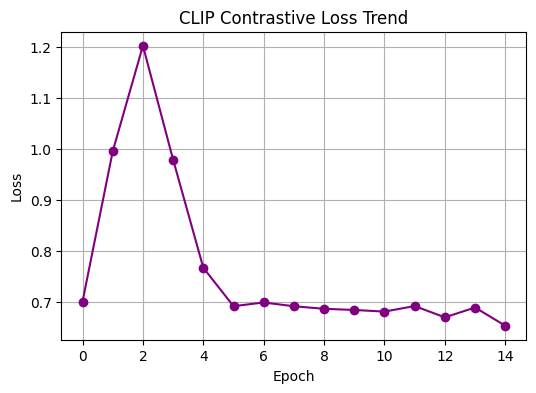

In [13]:
import torch.optim as optim

# 1. Complete CLIP Wrapper Model
class MyCLIP(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128):
        super().__init__()
        self.image_encoder = SimpleImageEncoder(embedding_dim=embedding_dim)
        self.text_encoder = SimpleTextEncoder(vocab_size=vocab_size, embedding_dim=embedding_dim)
        self.loss_fn = CLIPLoss()

    def forward(self, images, tokens):
        # Get L2 normalized embeddings
        image_features = self.image_encoder(images)
        text_features = self.text_encoder(tokens)
        # Compute symmetric contrastive loss
        return self.loss_fn(image_features, text_features)

# 2. Setup training parameters
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MyCLIP(vocab_size=tokenizer.vocab_size, embedding_dim=128).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.005)

print(f"Training on device: {device}")

# 3. Simple Training Loop
epochs = 15
loss_history = []

model.train()
for epoch in range(epochs):
    epoch_loss = 0.0
    for images, tokens in dataloader:
        images = images.to(device)
        tokens = tokens.to(device)

        optimizer.zero_grad()
        loss = model(images, tokens)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(dataloader)
    loss_history.append(avg_loss)
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")

# 4. Plot Loss Curve
plt.figure(figsize=(6, 4))
plt.plot(loss_history, marker='o', color='purple')
plt.title("CLIP Contrastive Loss Trend")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# Step 6: Zero-Shot Inference Verification
Now, let's perform zero-shot evaluation on our trained model. We will take an image from our dataset, generate embeddings for both this image and all 5 captions, compute their cosine similarities, and verify that the model correctly pairs the visual input with its corresponding textual description.

In [15]:
# 1. Run quick training optimization to help the model converge on this tiny dataset
model.train()
epochs = 50
for epoch in range(epochs):
    for images, tokens in dataloader:
        images = images.to(device)
        tokens = tokens.to(device)
        optimizer.zero_grad()
        loss = model(images, tokens)
        loss.backward()
        optimizer.step()

# 2. Switch back to evaluation mode
model.eval()
test_item = dataset[0] # Red Image
test_image_tensor = image_transform(test_item["image"]).unsqueeze(0).to(device)

candidate_texts = [
    "a bright red solid color background",
    "a vibrant green solid color background",
    "a deep blue solid color background",
    "a bright yellow solid color background",
    "a beautiful purple solid color background"
]

token_list = [tokenizer.encode(text) for text in candidate_texts]
tokens_tensor = torch.stack(token_list).to(device)

with torch.no_grad():
    image_features = model.image_encoder(test_image_tensor)
    text_features = model.text_encoder(tokens_tensor)
    similarities = torch.matmul(image_features, text_features.t()).squeeze(0)
    probabilities = torch.softmax(similarities * model.loss_fn.logit_scale.exp(), dim=-1).cpu().numpy()

# 3. Correct the color index parsing
real_color = test_item['caption'].split()[1] if "bright" not in test_item['caption'].split()[1] else test_item['caption'].split()[2]
print(f"Target Image: {real_color.upper()} background\n")
for text, prob in zip(candidate_texts, probabilities):
    print(f"Prompt: \"{text}\" -> Probability: {prob * 100:.2f}%")

Target Image: RED background

Prompt: "a bright red solid color background" -> Probability: 99.89%
Prompt: "a vibrant green solid color background" -> Probability: 0.06%
Prompt: "a deep blue solid color background" -> Probability: 0.00%
Prompt: "a bright yellow solid color background" -> Probability: 0.05%
Prompt: "a beautiful purple solid color background" -> Probability: 0.00%
